# 20 · Eccentricity from a stellar density

**Level:** intermediate · **Prerequisites:** [11](11_your_first_fit_with_is.ipynb); [14](14_profile_importance_sampling.ipynb) helps · **Run time:** ~1 min

**Covers:** the photoeccentric effect; `FitResult.reweight_density`; one circular fit for any stellar density and any prior on $(e, \omega)$; how the method works, step by step; why it needs a Jacobian and has to move the transit centre; a check against dynesty and against a grid, and what to do when references disagree; calibration on 1100 simulated light curves; where it stops being right

A transit tells you the duration, not the orbit. Assume a circular orbit, and the duration implies a stellar density $\rho_{\rm circ}$ through $a/R_\star$ and Kepler's third law. On an eccentric orbit the planet crosses the star faster or slower than that, depending on where in the orbit the transit happens, and the implied density comes out wrong by a known factor:

$$\frac{\rho_{\rm circ}}{\rho_\star} = g^3, \qquad g = \frac{1 + e\sin\omega}{\sqrt{1 - e^2}} .$$

This is the photoeccentric effect ([Dawson & Johnson 2012](https://ui.adsabs.harvard.edu/abs/2012ApJ...756..122D)). So if you know the density of the star, say from spectroscopy or asteroseismology, the transit constrains $e$ and $\omega$. Fitting $e$ and $\omega$ directly is slow: these two parameters are almost degenerate along a curve, and the posterior is awkward for any sampler. [MacDougall et al. (2023)](https://arxiv.org/abs/2307.07070) fit a circular orbit first, and then get $e$ and $\omega$ by importance sampling. pizzetti does the same in one call, after `fit()`, with no new likelihood evaluation.

In [1]:
import json
import math
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pizzetti

warnings.filterwarnings("ignore", category=RuntimeWarning)

G = 6.6743e-8                                  # cm3 / g / s2
PER, SIGMA = 10.0, 250e-6
RHO_STAR, RHO_SD = 1.41, 0.141                 # g/cm3: a star like the Sun, its density known to 10 %
A_TRUE = (RHO_STAR * G * (PER * 86400.0) ** 2 / (3 * math.pi)) ** (1 / 3)
T = np.concatenate([np.arange(-0.35, 0.35, 5 / 1440) + i * PER for i in range(8)])      # eight transits at 5 min


def density(a, per=PER):
    return 3 * np.pi * a ** 3 / (G * (per * 86400.0) ** 2)


def params(t0, rp, a, b_orbit, e, w):
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a, p.ecc, p.w, p.limb_dark, p.u = t0, PER, rp, a, e, w, "quadratic", [0.4, 0.25]
    p.inc = math.degrees(math.acos(b_orbit / a))
    return p


def simulate(rp, e, w, b_conj, seed):
    # b_conj is the impact parameter of the transit; b = a cos(inc) = b_conj / r_conj, r_conj = (1 - e^2) / (1 + e sin w)
    p = params(0.0, rp, A_TRUE, b_conj * (1 + e * math.sin(math.radians(w))) / (1 - e * e), e, w)
    return pizzetti.TransitModel(p, T).light_curve(p) + SIGMA * np.random.default_rng(seed).standard_normal(T.size)


def circular_model(y, rp, b_conj):
    # a circular orbit, with bounds on a wide enough for the circular a/R* of any orbit
    p = params(0.0, rp, A_TRUE, min(b_conj, 0.9), 0.0, 90.0)
    return pizzetti.MarginalTransitModel(p, T, y, SIGMA, free=("t0", "rp", "a", "b"),
                                         bounds=dict(t0=(-0.08, 0.08), rp=(1e-3, 0.3), a=(1.5, 300.0)))


def wq(x, w, qs=(0.16, 0.5, 0.84)):
    i = np.argsort(x)
    c = np.cumsum(w[i])
    return np.interp(qs, c / c[-1], x[i])

## 1. One call

We simulate a planet on an orbit with $e = 0.5$, $\omega = 60°$, and fit it as if the orbit were circular. Nothing about the fit knows about eccentricity. Then one more line, with the density of the star:

In [2]:
E_TRUE, W_TRUE = 0.5, 60.0
y = simulate(rp=0.05, e=E_TRUE, w=W_TRUE, b_conj=0.4, seed=1)
model = circular_model(y, rp=0.05, b_conj=0.4)

t_start = time.perf_counter()
fit = model.fit(seed=1, n=4000)
t_fit = time.perf_counter() - t_start

t_start = time.perf_counter()
res = fit.reweight_density(rho=(RHO_STAR, RHO_SD), seed=2)
t_rw = time.perf_counter() - t_start

print(f"fit: {fit.diagnostics['n_eval']} evaluations, {t_fit:.1f} s; reweighting: {t_rw:.2f} s, evaluations added: {res.diagnostics['n_eval'] - fit.diagnostics['n_eval']}\n")
print(res.summary())
print("\n", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in res.diagnostics["density"].items()})

fit: 11255 evaluations, 2.1 s; reweighting: 0.20 s, evaluations added: 0

               median     -1sigma     +1sigma
t0       4.066076e-05    0.000297    0.000271
rp         0.04922199    0.000591    0.000997
a            19.57178       0.664        0.61
b             0.64597       0.408       0.299
q1          0.5988737       0.156       0.198
q2           0.147479       0.085       0.104
f0          0.9999886    6.84e-06    6.76e-06
ecc         0.5795485      0.0938       0.171
w            91.97982        64.2          63
b_conj      0.2937638       0.191       0.179
rho          1.418173       0.139       0.137

 {'rho': 1.41, 'sd': 0.141, 'ecc_max': 0.92, 'ess': 2810.335, 'ess_parents': 1488.243, 'a_wall_mass': 0.0, 'passes': 1}


The result is an ordinary `FitResult`, with the columns of the fit and four more. `a`, `b` and `t0` now belong to the eccentric orbit, `b_conj` is the impact parameter of the transit, the one the fit measured, and `rho` is the density of each draw. Use `weighted_samples` and `weights` for plots, as usual.

Here is what happened. The circular fit implies a density several times that of the star, and that discrepancy is the whole signal:

e = 0.58 +0.17 -0.09; truth 0.5.  P(e > 0.2) = 1.000


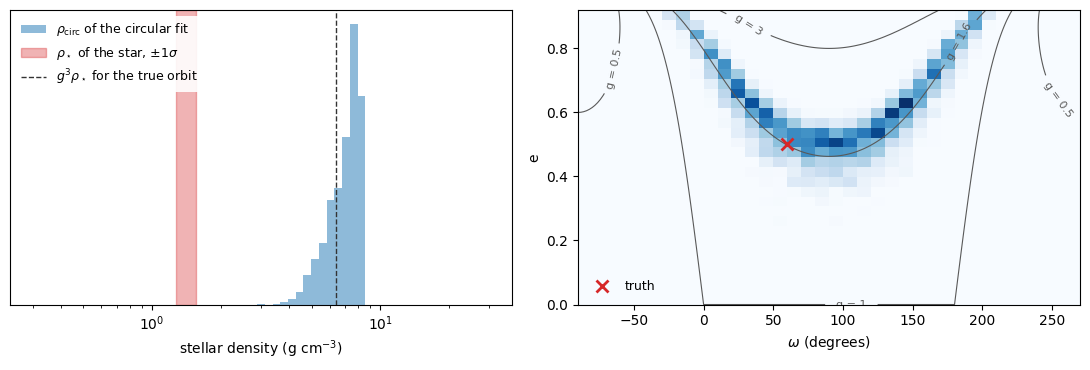

In [3]:
Sc, Lc, wc = fit.weighted_samples, fit.labels, fit.weights
S, L, w = res.weighted_samples, res.labels, res.weights
g_true = (1 + E_TRUE * math.sin(math.radians(W_TRUE))) / math.sqrt(1 - E_TRUE ** 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
rho_circ = density(Sc[:, Lc.index("a")])
ax.hist(rho_circ, bins=np.geomspace(0.3, 30, 60), weights=wc, histtype="stepfilled", color="C0", alpha=0.5, label=r"$\rho_{\rm circ}$ of the circular fit")
ax.axvspan(RHO_STAR - RHO_SD, RHO_STAR + RHO_SD, color="C3", alpha=0.35, label=r"$\rho_\star$ of the star, $\pm 1\sigma$")
ax.axvline(RHO_STAR * g_true ** 3, color="0.2", lw=1, ls="--", label=r"$g^3 \rho_\star$ for the true orbit")
ax.set_xscale("log")
ax.set_xlabel("stellar density (g cm$^{-3}$)")
ax.set_yticks([])
ax.legend(frameon=True, framealpha=0.9, edgecolor="none", fontsize=9, loc="upper left")

ax = axes[1]
h, xe, ye = np.histogram2d(S[:, L.index("w")], S[:, L.index("ecc")], bins=(36, 30), range=((-90, 270), (0, 0.92)), weights=w)
ax.pcolormesh(xe, ye, h.T, cmap="Blues", rasterized=True)
om, ee = np.meshgrid(np.linspace(-90, 270, 181), np.linspace(0, 0.92, 93))
gg = (1 + ee * np.sin(np.radians(om))) / np.sqrt(1 - ee ** 2)
cs = ax.contour(om, ee, gg, levels=[0.5, 1.0, 1.65, 3.0], colors="0.35", linewidths=0.8)
ax.clabel(cs, fmt="g = %.2g", fontsize=8)
ax.plot(W_TRUE, E_TRUE, "x", color="C3", ms=9, mew=2, label="truth")
ax.set_xlabel(r"$\omega$ (degrees)")
ax.set_ylabel("e")
ax.legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout()

qe = wq(S[:, L.index("ecc")], w)
print(f"e = {qe[1]:.2f} +{qe[2] - qe[1]:.2f} -{qe[1] - qe[0]:.2f}; truth {E_TRUE}.  P(e > 0.2) = {np.sum(w[S[:, L.index('ecc')] > 0.2]):.3f}")

The posterior follows a contour of $g$. That is the degeneracy: a transit measures one number, $g$, not two. The data can rule out a circular orbit here, since $g$ is far from one, but they leave a long banana in $(\omega, e)$. Its lower tip is the smallest eccentricity that can explain the density, so a posterior like this gives a robust *lower* limit on $e$.

## 2. What the method does

Why can a circular fit stand in for an eccentric one? The transit light curve depends on the orbit almost only through $(R_p/R_\star, b, T_{14}, t_0)$. These the circular fit has measured, whatever $e$ and $\omega$ are. So take each draw of the fit and:

1. draw $(e, \omega)$ from their prior;
2. find the $a/R_\star$ that gives this orbit the same duration: $\sin(\pi T_{14}\, g / P) = \sqrt{(1 + k)^2 - b^2}\,/\sqrt{a^2 - b_{\rm orbit}^2}$;
3. compute its density $\rho = 3\pi a^3 / (G P^2)$, and weight the draw by the prior on the density.

Step 3 has a catch. It is tempting to use the weight $N(\rho)$, and that is wrong. The fit has a prior flat in the *circular* $a/R_\star$, and we want one that is Gaussian in $\rho$. Both are statements about the same $T_{14}$, so the weight is the ratio of the two priors, each written as a density in $T_{14}$:

$$\text{weight} = N(\rho)\,\left|\frac{\partial\rho}{\partial T_{14}}\right| \Big/ \left|\frac{\partial a_{\rm circ}}{\partial T_{14}}\right| .$$

Here is the method by hand, with and without that factor, on a grazing transit. We use a light curve for which we have references: dynesty on the eccentric model, and a brute-force grid (section 4).

quantiles of e       16 %   50 %   84 %
by hand, Jacobian   0.131  0.371  0.661
by hand, N(rho)     0.160  0.431  0.714
reweight_density    0.135  0.377  0.668
grid                0.142  0.400  0.670
dynesty, seed 1     0.147  0.400  0.676
dynesty, seed 2     0.147  0.412  0.688


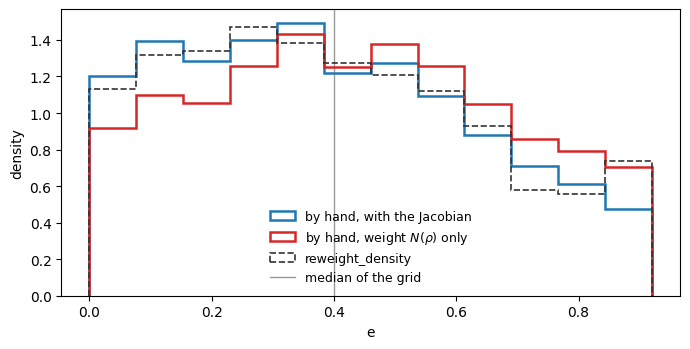

In [4]:
def by_hand(fit, rho, rho_sd, jacobian=True, ecc_max=0.92, repeats=50, seed=0):
    rng = np.random.default_rng(seed)
    S, L, w = fit.weighted_samples, fit.labels, fit.weights
    j = np.repeat(np.arange(len(S)), repeats)
    k, b, a_c = S[j, L.index("rp")], S[j, L.index("b")], S[j, L.index("a")]
    e, om = rng.uniform(0, ecc_max, len(j)), rng.uniform(-np.pi / 2, 3 * np.pi / 2, len(j))
    g = (1 + e * np.sin(om)) / np.sqrt(1 - e ** 2)
    b_orbit = b * (1 + e * np.sin(om)) / (1 - e ** 2)
    Q = (1 + k) ** 2 - b ** 2
    s_c = np.arcsin(np.sqrt(Q / (a_c ** 2 - b ** 2)))         # pi T14 / P, measured
    s = s_c * g
    a = np.sqrt(Q / np.sin(s) ** 2 + b_orbit ** 2)            # step 2
    r = density(a)                                            # step 3
    lw = np.log(w[j]) - 0.5 * ((r - rho) / rho_sd) ** 2
    if jacobian:
        da_c = Q * np.cos(s_c) / (a_c * np.sin(s_c) ** 3)     # |d a_circ / d s_c|
        da = Q * np.cos(s) * g / (a * np.sin(s) ** 3)         # |d a / d s_c| on this orbit
        lw += np.log(3 * r / a * da / da_c)
    lw[~(s < np.pi / 2) | ~np.isfinite(lw)] = -np.inf
    return e, np.exp(lw - np.max(lw))


with open(os.path.join("..", "testdata", "density_refs.json")) as f:
    REFS = json.load(f)
CASES = {"e40w090": (0.03, 0.40, 90.0, 0.40), "e40w270": (0.03, 0.40, 270.0, 0.40), "e05": (0.03, 0.05, 40.0, 0.40),
         "e70w180": (0.03, 0.70, 178.0, 0.30), "e40graz": (0.03, 0.40, 90.0, 0.985)}


def case_fit(case, seed=1, n=4000):
    rp, e, w, b_conj = CASES[case]
    return circular_model(simulate(rp, e, w, b_conj, seed=sum(map(ord, case))), rp, b_conj).fit(seed=seed, n=n)


fit_g = case_fit("e40graz")
e_with, w_with = by_hand(fit_g, RHO_STAR, RHO_SD, jacobian=True)
e_wo, w_wo = by_hand(fit_g, RHO_STAR, RHO_SD, jacobian=False)
r_g = fit_g.reweight_density((RHO_STAR, RHO_SD), seed=2)
e_m, w_m = r_g.weighted_samples[:, r_g.labels.index("ecc")], r_g.weights
refs_g = [q for q in REFS["runs"] if q["case"] == "e40graz"]
grid_g = next(q for q in REFS["grid"] if q["case"] == "e40graz")

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0, 0.92, 13)
ax.hist(e_with, bins=bins, weights=w_with, density=True, histtype="step", color="C0", lw=1.8, label="by hand, with the Jacobian")
ax.hist(e_wo, bins=bins, weights=w_wo, density=True, histtype="step", color="C3", lw=1.8, label=r"by hand, weight $N(\rho)$ only")
ax.hist(e_m, bins=bins, weights=w_m, density=True, histtype="step", color="0.2", lw=1.2, ls="--", label="reweight_density")
ax.axvline(grid_g["ecc"][2], color="0.6", lw=1, zorder=0, label="median of the grid")
ax.set_xlabel("e")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

print("quantiles of e       16 %   50 %   84 %")
for label, q in (("by hand, Jacobian", wq(e_with, w_with)), ("by hand, N(rho)", wq(e_wo, w_wo)), ("reweight_density", wq(e_m, w_m)),
                 ("grid", np.array(grid_g["ecc"])[1:4]), ("dynesty, seed 1", np.array(refs_g[0]["ecc"])[1:4]), ("dynesty, seed 2", np.array(refs_g[1]["ecc"])[1:4])):
    print(f"{label:18s}  " + "  ".join(f"{v:.3f}" for v in q))

Without the factor, the median of $e$ comes out at 0.43, against 0.40 to 0.41 from the references: too much mass at high eccentricity, with nothing in the diagnostics to tell you, since the weights look fine. `reweight_density` applies it.

## 3. Why the transit centre has to move

There is a second catch, which is easy to miss. On an eccentric orbit the middle of the transit is not at conjunction, because the planet speeds up or slows down on its way across. The offset is small, about a minute, which is why it does no harm to the shape of the posterior, but $t_0$ in pizzetti is the time of *conjunction*. A draw with the right duration but the old $t_0$ has its transit in the wrong place.

Compare a transit on $e = 0.7$, $\omega = 0°$ with a circular one of the same duration, without noise:

T14 = 177.5 min; the middle of the transit is -0.58 min from conjunction; depth 11877 ppm


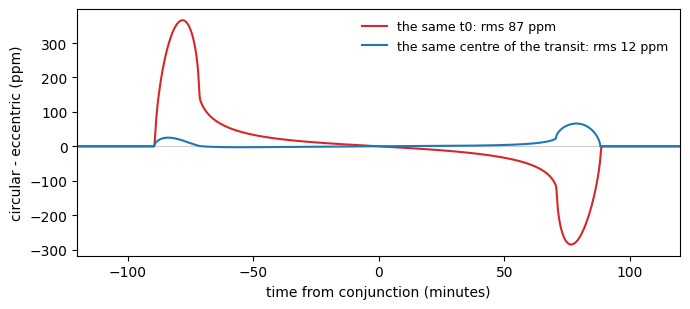

In [5]:
rp_d, b_d, e_d, w_d = 0.1, 0.3, 0.7, 0.0
b_orbit = b_d * (1 + e_d * math.sin(math.radians(w_d))) / (1 - e_d ** 2)
pe = params(0.0, rp_d, A_TRUE, b_orbit, e_d, w_d)
t_d = np.arange(-0.2, 0.2, 10 / 86400)
f_e = pizzetti.TransitModel(pe, t_d).light_curve(pe)
inside = t_d[f_e < 1 - 1e-12]
T14, mid = inside[-1] - inside[0], 0.5 * (inside[0] + inside[-1])

Q = (1 + rp_d) ** 2 - b_d ** 2
a_same = math.sqrt(Q / math.sin(math.pi * T14 / PER) ** 2 + b_d ** 2)     # the circular orbit with this duration
residual = {}
for label, t0 in (("the same t0", 0.0), ("the same centre of the transit", mid)):
    pc = params(t0, rp_d, a_same, b_d, 0.0, 90.0)
    residual[label] = 1e6 * (pizzetti.TransitModel(pc, t_d).light_curve(pc) - f_e)

fig, ax = plt.subplots(figsize=(7, 3.2))
for (label, r_), col in zip(residual.items(), ("C3", "C0")):
    ax.plot(1440 * t_d, r_, color=col, lw=1.5, label=f"{label}: rms {np.std(r_[np.abs(t_d - mid) < T14]):.0f} ppm")
ax.axhline(0, color="0.8", lw=0.8, zorder=0)
ax.set_xlim(-120, 120)
ax.set_xlabel("time from conjunction (minutes)")
ax.set_ylabel("circular - eccentric (ppm)")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
print(f"T14 = {1440 * T14:.1f} min; the middle of the transit is {1440 * mid:+.2f} min from conjunction; depth {1e6 * (1 - f_e.min()):.0f} ppm")

With the centre moved, the rms falls from 87 to 12 ppm. The rest is a small difference in shape, which section 5 comes back to. The first version of this method kept $t_0$ and took the duration from the usual constant-speed formula. In a calibration (section 5), the 95 % interval of $t_0$ held the truth only 54 % of the time, though everything else looked right. So `reweight_density` solves for the contact times on the Keplerian orbit, keeps the duration and the centre of the transit, and returns the $t_0$ of the eccentric orbit.

## 4. Against references, and when a reference is wrong

Dynesty over $(t_0, R_p/R_\star, a, b, e, \omega)$ on the eccentric forward model has no assumption about the shape of the transit. It takes 1.6 to 3 million evaluations per run, against 9000 to 39 000 here. We have two runs with 2000 live points on each of five light curves, in `testdata/density_refs.json`.

In [6]:
print("                         quantiles of e: 16 %, 50 %, 84 %        evaluations")
for case in CASES:
    r = case_fit(case).reweight_density((RHO_STAR, RHO_SD), seed=2)
    runs = [q for q in REFS["runs"] if q["case"] == case]
    ours = wq(r.weighted_samples[:, r.labels.index("ecc")], r.weights)
    print(f"{case:9s} reweight_density " + " ".join(f"{v:.3f}" for v in ours) + f"   {r.diagnostics['n_eval']:9d}")
    for q in runs:
        print(f"{'':9s} dynesty, seed {q['seed']}  " + " ".join(f"{v:.3f}" for v in np.array(q["ecc"])[1:4]) + f"   {q['ncall']:9d}")
    for q in REFS["grid"]:
        if q["case"] == case:
            print(f"{'':9s} grid             " + " ".join(f"{v:.3f}" for v in np.array(q["ecc"])[1:4]) + f"   ({q['cells']} cells)")

                         quantiles of e: 16 %, 50 %, 84 %        evaluations
e40w090   reweight_density 0.242 0.464 0.690        8825
          dynesty, seed 1  0.263 0.478 0.689     2724958
          dynesty, seed 2  0.259 0.467 0.696     2727659
e40w270   reweight_density 0.407 0.564 0.744        9944
          dynesty, seed 2  0.393 0.548 0.734     2717739
          dynesty, seed 1  0.412 0.561 0.736     2731182
e05       reweight_density 0.056 0.187 0.497        9676
          dynesty, seed 1  0.053 0.162 0.422     2620122
          dynesty, seed 2  0.065 0.197 0.504     2680655
e70w180   reweight_density 0.362 0.466 0.685        8684
          dynesty, seed 1  0.358 0.471 0.782     2961654
          dynesty, seed 2  0.368 0.499 0.775     2972357
          grid             0.364 0.467 0.703   (550 cells)
e40graz   reweight_density 0.135 0.377 0.668       38521
          dynesty, seed 1  0.147 0.400 0.676     1639165
          dynesty, seed 2  0.147 0.412 0.688     1616863
         

Three of the five agree about as well as the two dynesty runs agree with each other. On `e70w180`, the upper quantile disagrees: 0.69 here, 0.78 from both dynesty runs. Two seeds that agree, 2000 live points, and a far more direct calculation. Surely dynesty is right?

Not here. We can settle it by a third method, which shares nothing with the other two: fix $(e, \omega)$, compute the four-dimensional integral of the eccentric likelihood over the other parameters, repeat on a grid of $(e, \omega)$, and read off $p(e, \omega\,|\,\text{data})$. That took 552 calls of `profile_is` (`python tests/_density_refs.py grid`), and it comes out at 0.70. Notebook 19 found the same thing about nested sampling on thin ridges. Two runs of one sampler agreeing with each other shows that they share a result, not that the result is right. When a reference matters, get a second one that works differently.

The grid also shows where this method is a little off. On the grazing `e40graz`, it agrees with dynesty and puts the median of $e$ at 0.40, against 0.38 here, about 0.1 posterior widths. And on `e70w180` the far tail goes the other way: at 97.5 % the grid and dynesty both say 0.90, this method 0.87.

## 5. Calibration

A handful of light curves does not show that a method is right in general. Simulation-based calibration does: draw the truth from the prior, simulate, fit, and find the rank of the truth in its posterior. If the posterior is right, ranks are uniform. We did this for 1100 light curves (`python tests/_density_calibration.py`): density known to 3, 10 or 30 %, $P$ from 2 to 30 days, $e$ up to 0.92, every $\omega$, $b$ up to grazing, and noise from 100 to 1000 ppm, simulated with the eccentric model and fitted with the circular one. The ranks are stored in `testdata/density_calibration.json`:

fraction of truths in the 68 % / 95 % interval
                             ecc          w        rho         rp     b_conj         t0
all             1100   0.68/0.95  0.70/0.96  0.67/0.95  0.68/0.95  0.67/0.95  0.69/0.96
S/N < 100        288   0.67/0.95  0.71/0.94  0.61/0.93  0.68/0.94  0.66/0.97  0.67/0.93
S/N 100-300      298   0.67/0.96  0.66/0.95  0.67/0.95  0.68/0.97  0.73/0.98  0.69/0.97
S/N 300-1000     381   0.67/0.94  0.72/0.96  0.70/0.95  0.69/0.94  0.65/0.96  0.69/0.96
S/N > 1000       133   0.74/0.95  0.72/0.98  0.69/0.96  0.66/0.92  0.64/0.86  0.70/0.98
grazing          191   0.65/0.94  0.67/0.97  0.65/0.92  0.71/0.95  0.65/0.95  0.66/0.96

median ESS 3745, counted in draws of the fit 1567; median 13984 evaluations; fit passes its diagnostics: 0.999


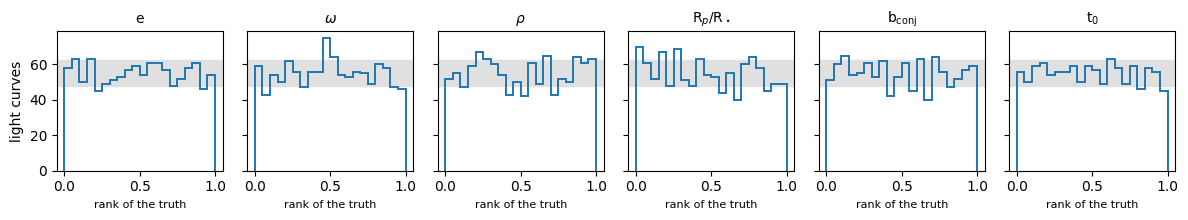

In [7]:
with open(os.path.join("..", "testdata", "density_calibration.json")) as f:
    runs = json.load(f)["runs"]
snr = np.array([q["snr"] for q in runs])
NAMES = (("ecc", "e"), ("w", r"$\omega$"), ("rho", r"$\rho$"), ("rp", r"R$_p$/R$_\star$"), ("b_conj", r"b$_{\rm conj}$"), ("t0", r"t$_0$"))

fig, axes = plt.subplots(1, 6, figsize=(12, 2.3), sharey=True)
nb = 20
for ax, (key, label) in zip(axes, NAMES):
    ax.axhspan(len(runs) / nb - math.sqrt(len(runs) / nb), len(runs) / nb + math.sqrt(len(runs) / nb), color="0.88", zorder=0)
    ax.hist([q["ranks"][key] for q in runs], bins=nb, range=(0, 1), histtype="step", color="C0", lw=1.4)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("rank of the truth", fontsize=8)
axes[0].set_ylabel("light curves")
fig.tight_layout()


def coverage(rows, field, key):
    r = np.array([q[field][key] for q in rows])
    return np.mean((r > 0.16) & (r < 0.84)), np.mean((r > 0.025) & (r < 0.975))


GROUPS = [("all", runs), ("S/N < 100", [q for q in runs if q["snr"] < 100]), ("S/N 100-300", [q for q in runs if 100 <= q["snr"] < 300]),
          ("S/N 300-1000", [q for q in runs if 300 <= q["snr"] < 1000]), ("S/N > 1000", [q for q in runs if q["snr"] >= 1000]),
          ("grazing", [q for q in runs if q["b_conj"] > 1 - q["rp"]])]
print("fraction of truths in the 68 % / 95 % interval\n" + " " * 21 + "".join(f"{k:>11s}" for k, _ in NAMES))
for name, rows in GROUPS:
    print(f"{name:14s} {len(rows):5d} " + "".join("  {:.2f}/{:.2f}".format(*coverage(rows, "ranks", k)) for k, _ in NAMES))
print(f"\nmedian ESS {np.median([q['ess'] for q in runs]):.0f}, counted in draws of the fit {np.median([q['ess_parents'] for q in runs]):.0f}; "
      f"median {np.median([q['n_eval'] for q in runs]):.0f} evaluations; fit passes its diagnostics: {np.mean([q['is_ok'] for q in runs]):.3f}")

The ranks are flat, up to their counting noise (grey band), and the intervals hold about what they should, for all $e$ and $\omega$ and for grazing transits.

The exception is at very high S/N, where the posterior is so tight that the small remaining difference in transit shape matters. Above an S/N of 1000, the 95 % interval of $b$ holds the truth 86 % of the time, and that of $R_p/R_\star$ 92 %. (A caution on reading this table: S/N here comes from the true depth, so the groups select on the truth, and low-S/N rows in $R_p/R_\star$ are not expected to be perfectly uniform. Above S/N 1000 the posterior is so narrow that this hardly matters.) $e$, $\omega$ and $\rho$ remain fine, which is what the method is for. If you need $b$ to better than that at such S/N, sample $e$ and $\omega$ directly.

**Would a correction help?** An obvious idea: weight the final draws by the ratio of the eccentric to the circular likelihood. It takes a few thousand evaluations and looks as if it removed the assumption altogether. We built it and calibrated it, and it makes things worse:

In [8]:
print(" " * 34 + "".join(f"{k:>7s}" for k, _ in NAMES[:2]) + f"{'t0':>7s}{'b':>7s}")
for name, rows in (GROUPS[0], GROUPS[4], GROUPS[5]):
    for field, label in (("ranks", "the mapping alone"), ("ranks_ratio", "with the ratio")):
        print(f"{name:12s} {label:20s}  " + "".join(f"{coverage(rows, field, k)[1]:7.2f}" for k in ("ecc", "w", "t0", "b_conj")))
print(f"\nfraction of the 95 % interval that holds the truth. k-hat of the ratio > 0.7 on {np.mean([q['khat'] > 0.7 for q in runs]):.0%} of the light curves")

                                      ecc      w     t0      b
all          the mapping alone        0.95   0.96   0.96   0.95
all          with the ratio           0.92   0.92   0.91   0.95
S/N > 1000   the mapping alone        0.95   0.98   0.98   0.86
S/N > 1000   with the ratio           0.82   0.86   0.82   0.86
grazing      the mapping alone        0.94   0.97   0.96   0.95
grazing      with the ratio           0.88   0.90   0.87   0.92

fraction of the 95 % interval that holds the truth. k-hat of the ratio > 0.7 on 58% of the light curves


The mapped draws have about the right width but sit a little off the centre of the eccentric posterior. The ratio does not move them; it only keeps those that happen to lie closest, which makes the intervals too narrow. An importance weight can correct a distribution only where the proposal is broader than the target. That is why `reweight_density` has no such option, and why it adds no likelihood evaluation.

## 6. One fit, any prior

The cost is all in the fit, so trying other priors is free. Each line below takes a fraction of a second. `log_prior` gets $e$ and $\omega$ in degrees. Two common choices: the [Kipping (2013)](https://ui.adsabs.harvard.edu/abs/2013MNRAS.434L..51K) Beta distribution, fitted to radial-velocity planets, and the geometric transit probability, $\propto (1 + e\sin\omega)/(1 - e^2)$. The default prior is flat in $e$, $\omega$ and $b$, without that factor, so add it if you want the population of orbits that transit.

prior                                 e: 16 %, 50 %, 84 %     ESS    seconds
density known to 3 %                 0.490 0.572 0.755    2615  0.21
density known to 10 %                0.486 0.580 0.750    2810  0.20
density known to 30 %                0.460 0.586 0.759    8257  0.34
flat in e, omega                     0.486 0.580 0.750    2810  0.20
Kipping (2013) Beta                  0.453 0.524 0.622    2041  0.23
with the transit probability         0.499 0.605 0.795    2740  0.24


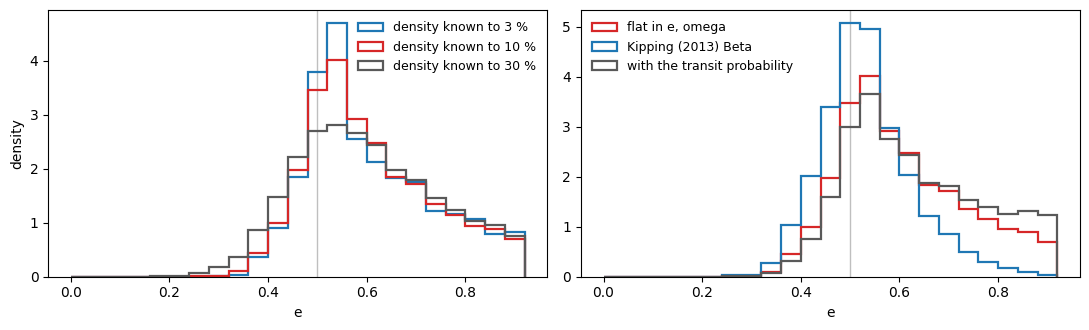

In [9]:
def beta_kipping(e, w):
    return (0.867 - 1) * np.log(e) + (3.03 - 1) * np.log1p(-e)


def transit_probability(e, w):
    return np.log1p(e * np.sin(np.radians(w))) - np.log1p(-e ** 2)


fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
bins = np.linspace(0, 0.92, 24)
print("prior                                 e: 16 %, 50 %, 84 %     ESS    seconds")
for ax, rows in zip(axes, ((("density known to 3 %", dict(rho=(RHO_STAR, 0.03 * RHO_STAR)), "C0"), ("density known to 10 %", dict(rho=(RHO_STAR, RHO_SD)), "C3"), ("density known to 30 %", dict(rho=(RHO_STAR, 0.3 * RHO_STAR)), "0.35")),
                           (("flat in e, omega", dict(rho=(RHO_STAR, RHO_SD)), "C3"), ("Kipping (2013) Beta", dict(rho=(RHO_STAR, RHO_SD), log_prior=beta_kipping), "C0"), ("with the transit probability", dict(rho=(RHO_STAR, RHO_SD), log_prior=transit_probability), "0.35")))):
    for label, kw, col in rows:
        t_start = time.perf_counter()
        r = fit.reweight_density(seed=2, **kw)
        dt = time.perf_counter() - t_start
        x = r.weighted_samples[:, r.labels.index("ecc")]
        ax.hist(x, bins=bins, weights=r.weights, density=True, histtype="step", color=col, lw=1.6, label=label)
        q = wq(x, r.weights)
        print(f"{label:36s} " + " ".join(f"{v:.3f}" for v in q) + f"  {r.diagnostics['density']['ess']:6.0f}  {dt:.2f}")
    ax.axvline(E_TRUE, color="0.75", lw=1, zorder=0)
    ax.set_xlabel("e")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("density")
fig.tight_layout()

A tighter density narrows the banana only so far: the width of $e$ comes from not knowing $\omega$, and no density measurement can remove that. This is a limit of the transit, not of the method. The prior on $e$ matters a lot, so state it.

## 7. When to be careful

| Situation | What happens | What to do |
|---|---|---|
| S/N above about 1000 | The intervals of `b_conj` and `rp` are too narrow, those of `e`, `w`, `rho` are fine | Sample `ecc` and `w` directly if you need `b` |
| Bounds on `a` cut the circular posterior | Orbits that need a circular $a/R_\star$ beyond them cannot be reached; `density["a_wall_mass"]` and a warning | Fit with wide bounds: `a=(1.5, 300)` here |
| A very narrow density, or one the fit barely allows | Few draws survive; `density["ess"]`, `density["ess_parents"]` and a warning | Raise `n` in `fit()`. `ess_parents` counts distinct draws of the fit, and more repeats cannot raise it beyond them |
| Orbits passing close to the star | Excluded when $a(1 - e) \le 1 + R_p/R_\star$. Within a few stellar radii the transit shape changes | Check whether such orbits dominate your posterior |
| A fit with `ecc` or `w`, or an eclipse | Refused | Fit a transit with `ecc=0` |
| A `log_prior` in the fit | It stays in the weights | It must not involve `a`, or it counts twice |
| You need the evidence | `lnz` is nan: the one of the circular fit does not apply | Use dynesty on the eccentric model |
| A density with an asymmetric posterior | Only a Gaussian is implemented | Compute the weights by hand as in section 2 |

## What you learned

- A circular fit measures $(R_p/R_\star, b, T_{14}, t_0)$, which barely depend on $e$ and $\omega$. Its density is off by $g^3$, and that is the photoeccentric effect.
- `fit.reweight_density(rho=(mean, sd))` gives $e$, $\omega$ and the eccentric orbit, with no new likelihood evaluation, and any prior on $(e, \omega)$ costs a fraction of a second.
- It needs the exact Jacobian and has to keep the centre of the transit. Neither shows up in the weights if it is missing, and calibration is what caught the second.
- It is calibrated on 1100 prior-drawn light curves, up to an S/N of about 1000 for all parameters, and beyond that for $e$, $\omega$ and $\rho$.
- References can be wrong too: two agreeing runs of one sampler are not a second opinion.

**Next:** [tutorial 15](15_when_the_profile_is_not_enough.ipynb) for grazing posteriors, [tutorial 16](16_is_against_mcmc.ipynb) for how to test a sampler, [the theory](https://pizzetti.readthedocs.io/en/latest/marginal.html).